# Projeto Aplicado II - EDA e Tratamento de Dados - Grupo Schema 


In [7]:
# ==============================================================================
# ITEM A: Definição de Bibliotecas e Pacotes da Linguagem Python
# ==============================================================================

import re
import string
import warnings
warnings.filterwarnings('ignore')

# Manipulação e Estruturação de Dados
import pandas as pd
import numpy as np

# Visualização de Dados e Gráficos
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Processamento de Linguagem Natural (NLP)
import nltk
from nltk.corpus import stopwords

# Download dos recursos necessários de stopwords para o português
nltk.download('stopwords')
stop_words_pt = set(stopwords.words('portuguese'))

print("Bibliotecas e pacotes importados com sucesso!")

Bibliotecas e pacotes importados com sucesso!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\dhm96\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Total de registros na base original: 99224
Total de avaliações com comentários de texto válidos: 40977


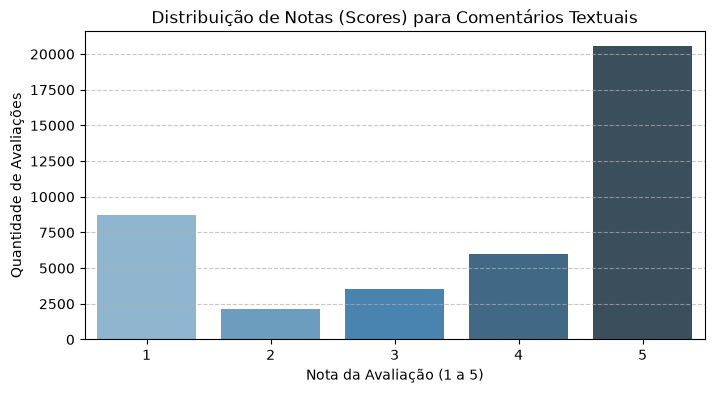

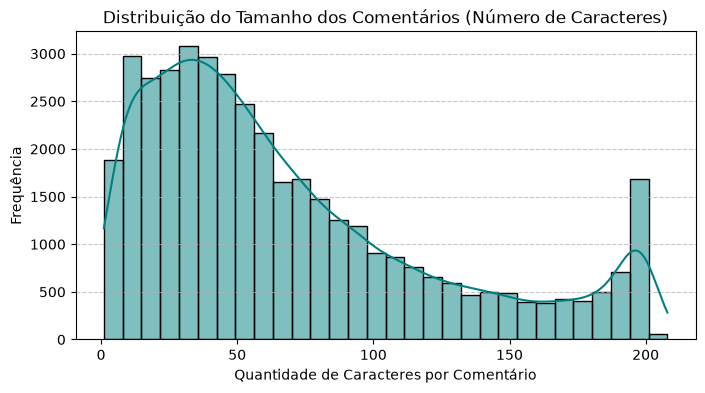

In [8]:
# ==============================================================================
# ITEM B: Definição da Base de Dados e Análise Exploratória (EDA)
# ==============================================================================

# 1. Carregamento da base de dados de avaliações de pedidos
df_reviews = pd.read_csv('olist_order_reviews_dataset.csv')

print(f"Total de registros na base original: {len(df_reviews)}")

# 2. Filtragem de dados: mantendo apenas avaliações que possuem comentário em texto
df_text = df_reviews[df_reviews['review_comment_message'].notnull()].copy()
print(f"Total de avaliações com comentários de texto válidos: {len(df_text)}")

# 3. Análise da distribuição de Notas (review_score)
plt.figure(figsize=(8, 4))
sns.countplot(data=df_text, x='review_score', palette='Blues_d')
plt.title('Distribuição de Notas (Scores) para Comentários Textuais')
plt.xlabel('Nota da Avaliação (1 a 5)')
plt.ylabel('Quantidade de Avaliações')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 4. Análise do Comprimento/Tamanho do Texto
df_text['tamanho_texto'] = df_text['review_comment_message'].apply(lambda x: len(str(x)))

plt.figure(figsize=(8, 4))
sns.histplot(data=df_text, x='tamanho_texto', bins=30, kde=True, color='teal')
plt.title('Distribuição do Tamanho dos Comentários (Número de Caracteres)')
plt.xlabel('Quantidade de Caracteres por Comentário')
plt.ylabel('Frequência')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [9]:
# ==============================================================================
# ITEM C: Tratamento e Preparação da Base de Dados Textual
# ==============================================================================

# 1. Remoção de avaliações neutras (Nota 3) para definir um problema binário claro
df_clean = df_text[df_text['review_score'] != 3].copy()

# 2. Rotulagem do Alvo (Target): 0 = Negativo (Notas 1 e 2) | 1 = Positivo (Notas 4 e 5)
df_clean['sentimento'] = df_clean['review_score'].apply(lambda x: 1 if x >= 4 else 0)

print("Proporção das classes (Sentimentos):")
print(df_clean['sentimento'].value_counts(normalize=True).map('{:.2%}'.format))

# 3. Função de Tratamento e Normalização do Texto
def limpar_texto(texto):
    if not isinstance(texto, str):
        return ""
    texto = texto.lower() # Converte para minúsculas
    texto = re.sub(r'\d+', '', texto) # Remove números
    texto = texto.translate(str.maketrans('', '', string.punctuation)) # Remove pontuações/símbolos
    palavras = texto.split()
    palavras = [p for p in palavras if p not in stop_words_pt] # Remove stopwords
    return ' '.join(palavras)

# Aplicação do tratamento na coluna de texto
df_clean['texto_limpo'] = df_clean['review_comment_message'].apply(limpar_texto)

# Display dos primeiros exemplos tratados
print("\n--- Amostra do Tratamento Textual ---")
df_clean[['review_comment_message', 'texto_limpo', 'sentimento']].head()

Proporção das classes (Sentimentos):
sentimento
1    70.90%
0    29.10%
Name: proportion, dtype: str

--- Amostra do Tratamento Textual ---


,review_comment_message,texto_limpo,sentimento
3,Recebi bem antes do prazo estipulado.,recebi bem antes prazo estipulado,1
4,Parabéns lojas lannister adorei comprar pela I...,parabéns lojas lannister adorei comprar intern...,1
9,aparelho eficiente. no site a marca do aparelh...,aparelho eficiente site marca aparelho impress...,1
12,"Mas um pouco ,travando...pelo valor ta Boa.\r\n",pouco travandopelo valor ta boa,1
15,"Vendedor confiável, produto ok e entrega antes...",vendedor confiável produto ok entrega antes prazo,1


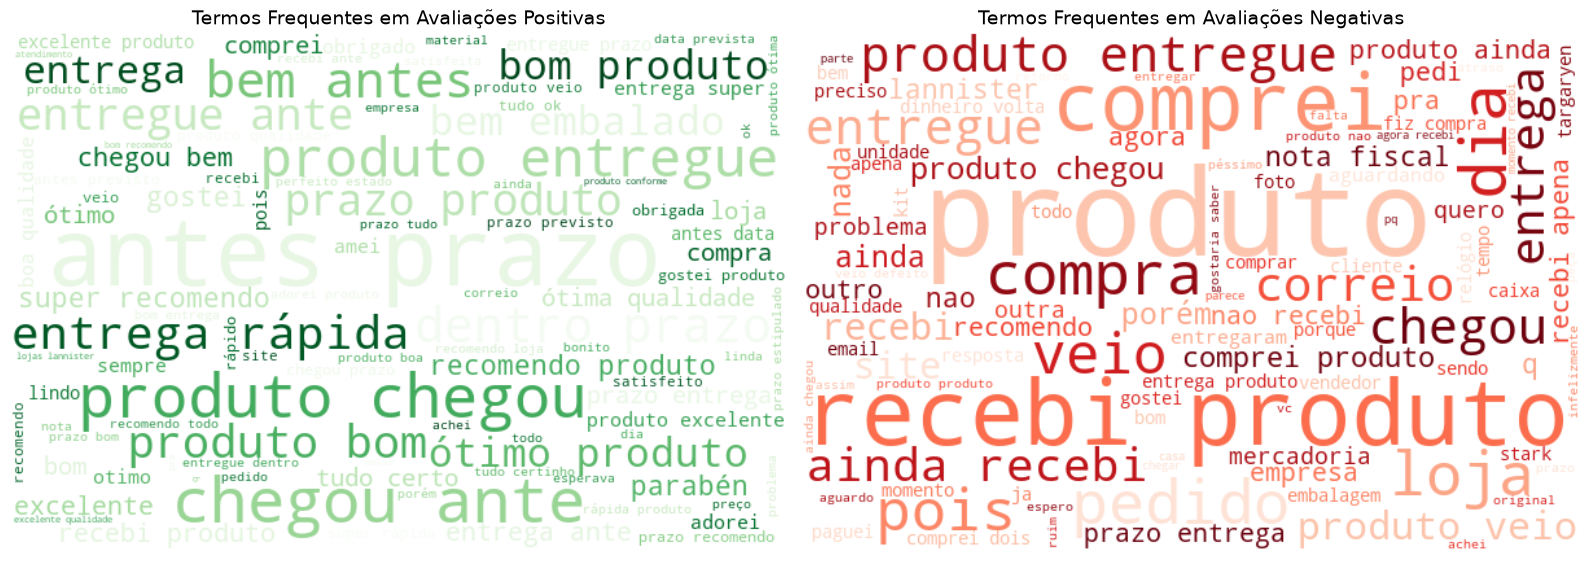

In [4]:
# ==============================================================================
# ITEM C (continuação): Visualização da Nuvem de Palavras (WordCloud)
# ==============================================================================

texto_positivo = " ".join(df_clean[df_clean['sentimento'] == 1]['texto_limpo'])
texto_negativo = " ".join(df_clean[df_clean['sentimento'] == 0]['texto_limpo'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Nuvem de Palavras - Sentimento Positivo
wc_pos = WordCloud(width=600, height=400, background_color='white', colormap='Greens', max_words=100).generate(texto_positivo)
axes[0].imshow(wc_pos, interpolation='bilinear')
axes[0].set_title('Termos Frequentes em Avaliações Positivas', fontsize=14)
axes[0].axis('off')

# Nuvem de Palavras - Sentimento Negativo
wc_neg = WordCloud(width=600, height=400, background_color='white', colormap='Reds', max_words=100).generate(texto_negativo)
axes[1].imshow(wc_neg, interpolation='bilinear')
axes[1].set_title('Termos Frequentes em Avaliações Negativas', fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [10]:
# ==============================================================================
# ITEM C (Continuação): Divisão, Vetorização (TF-IDF) e Treinamento do Modelo
# ==============================================================================

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# 1. Definição das variáveis
X = df_clean['texto_limpo']
y = df_clean['sentimento']

# 2. Divisão em Treino (80%) e Teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Vetorização por TF-IDF (Conversão do texto limpo em matriz numérica)
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# 4. Treinamento do Modelo
modelo_sentimento = LogisticRegression(max_iter=1000)
modelo_sentimento.fit(X_train_tfidf, y_train)

print("✅ Preparação, Vetorização e Treinamento do modelo concluídos com sucesso!")

✅ Preparação, Vetorização e Treinamento do modelo concluídos com sucesso!


In [22]:
# ==============================================================================
# TESTE PRÁTICO DO MODELO (Amostra / Validação Manual)
# ==============================================================================

# 1. Função para testar frases novas
def testar_comentario_novo(texto):
    # Passo A: Aplicar a mesma limpeza de texto criada no Item (c)
    texto_processado = limpar_texto(texto)
    
    # Passo B: Vetorizar a frase usando o MESMO vectorizer ajustado no treino
    vetorizado = vectorizer.transform([texto_processado])
    
    # Passo C: Prever a classe (0 = Negativo, 1 = Positivo) e a probabilidade (confiança)
    predicao = modelo_sentimento.predict(vetorizado)[0]
    probabilidade = modelo_sentimento.predict_proba(vetorizado)[0]
    
    # Passo D: Formatar o resultado
    sentimento = "POSITIVO 😀" if predicao == 1 else "NEGATIVO 😡"
    confianca = probabilidade[predicao] * 100
    
    print(f"Texto Original: '{texto}'")
    print(f"Texto Limpo:    '{texto_processado}'")
    print(f"Resultado:      {sentimento} (Confiança do modelo: {confianca:.2f}%)\n" + "-"*60)

# 2. Testando com uma lista de frases de exemplo
frases_teste = [
    "O produto é maravilhoso, chegou antes do prazo e muito bem embalado!",
    "Péssimo atendimento, o pedido veio quebrado e a loja não responde.",
    "O produto é razoável pelo preço, mas demorou um pouco.",
    "Comprei e não recebi. Quero meu dinheiro de volta."
]



print("=== TESTE DE INFERÊNCIA DO MODELO TREINADO ===\n")
for frase in frases_teste:
    testar_comentario_novo(frase)

#TESTE AO VIVO
print(60*"-")
TESTE = str(input("Escreva seu depoimento:"))

testar_comentario_novo(TESTE)

=== TESTE DE INFERÊNCIA DO MODELO TREINADO ===

Texto Original: 'O produto é maravilhoso, chegou antes do prazo e muito bem embalado!'
Texto Limpo:    'produto maravilhoso chegou antes prazo bem embalado'
Resultado:      POSITIVO 😀 (Confiança do modelo: 99.83%)
------------------------------------------------------------
Texto Original: 'Péssimo atendimento, o pedido veio quebrado e a loja não responde.'
Texto Limpo:    'péssimo atendimento pedido veio quebrado loja responde'
Resultado:      NEGATIVO 😡 (Confiança do modelo: 93.33%)
------------------------------------------------------------
Texto Original: 'O produto é razoável pelo preço, mas demorou um pouco.'
Texto Limpo:    'produto razoável preço demorou pouco'
Resultado:      POSITIVO 😀 (Confiança do modelo: 85.53%)
------------------------------------------------------------
Texto Original: 'Comprei e não recebi. Quero meu dinheiro de volta.'
Texto Limpo:    'comprei recebi quero dinheiro volta'
Resultado:      NEGATIVO 😡 (Conf

Escreva seu depoimento: tenebroso


Texto Original: 'tenebroso'
Texto Limpo:    'tenebroso'
Resultado:      POSITIVO 😀 (Confiança do modelo: 71.81%)
------------------------------------------------------------


In [23]:
# --- Métricas de Avaliação ---

print("=== RELATÓRIO DE DESEMPENHO DO MODELO ===")
print(classification_report(y_test, y_pred, target_names=['Negativo (0)', 'Positivo (1)']))

# Matriz de Confusão
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Negativo', 'Positivo'], cmap='Blues', ax=ax
)
plt.title('Matriz de Confusão')
plt.show()

=== RELATÓRIO DE DESEMPENHO DO MODELO ===


NameError: name 'classification_report' is not defined